# Arquitectura Vision Transformer para Fashion Mnist
## Proyecto de Aprendizaje Profundo

Diego Octavio Arias Incháustegui, Jose Alejandro Rojas Castro, Josh Haberkern,Steffany Mishell Lara Muy
*Instituto Tecnológico y de Estudios Superiores de Monterrey (ITESM)*

**Resumen**
TERMINAAAR
}

In [1]:

#Importar Librerías
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns  # Para visualizar matriz de confusión
from sklearn.manifold import TSNE  # Para t-SNE

In [2]:

# Cargar el conjunto de datos Fashion MNIST
(datos_entrenamiento_x, datos_entrenamiento_y), (datos_prueba_x, datos_prueba_y) = fashion_mnist.load_data()

# Preprocesamiento: Normalizar los valores de píxeles a [0,1] y agregar dimensión de canal (grayscale)
datos_entrenamiento_x = datos_entrenamiento_x.astype('float32') / 255.0
datos_prueba_x = datos_prueba_x.astype('float32') / 255.0

# Estandarización opcional (mean=0, std=1)
mean = np.mean(datos_entrenamiento_x)
std = np.std(datos_entrenamiento_x)
datos_entrenamiento_x = (datos_entrenamiento_x - mean) / std
datos_prueba_x = (datos_prueba_x - mean) / std

datos_entrenamiento_x = np.expand_dims(datos_entrenamiento_x, axis=-1)
datos_prueba_x = np.expand_dims(datos_prueba_x, axis=-1)

# Codificación one-hot para las etiquetas
datos_entrenamiento_y = to_categorical(datos_entrenamiento_y, num_classes=10)
datos_prueba_y = to_categorical(datos_prueba_y, num_classes=10)


In [3]:

# Definir la capa para extraer parches de la imagen
class ExtractorParches(layers.Layer):
    def __init__(self, tamano_parche):
        super(ExtractorParches, self).__init__()
        self.tamano_parche = tamano_parche

    def call(self, imagenes):
        tamano_lote = tf.shape(imagenes)[0]
        parches = tf.image.extract_patches(
            images=imagenes,
            sizes=[1, self.tamano_parche, self.tamano_parche, 1],
            strides=[1, self.tamano_parche, self.tamano_parche, 1],
            rates=[1, 1, 1, 1],
            padding='VALID',
        )
        dimension_parche = parches.shape[-1]
        numero_parches = parches.shape[1] * parches.shape[2]
        parches = tf.reshape(parches, [tamano_lote, numero_parches, dimension_parche])
        return parches


In [4]:

# Definir la capa para incrustar parches con posiciones
class IncrustacionParches(layers.Layer):
    def __init__(self, numero_parches, dimension_proyeccion):
        super(IncrustacionParches, self).__init__()
        self.numero_parches = numero_parches
        self.proyeccion = layers.Dense(units=dimension_proyeccion)
        self.incrustacion_posicional = layers.Embedding(
            input_dim=numero_parches, output_dim=dimension_proyeccion
        )

    def call(self, parches):
        posiciones = tf.range(start=0, limit=self.numero_parches, dtype=tf.int32)
        parches_proyectados = self.proyeccion(parches)
        incrustaciones_posicionales = self.incrustacion_posicional(posiciones)
        return parches_proyectados + incrustaciones_posicionales


In [5]:

# Definir el bloque del transformador
def bloque_transformador(dimension_incrustacion, numero_cabezas, unidades_ffn, tasa_dropout):
    entradas = layers.Input(shape=(None, dimension_incrustacion))
    
    # Normalización y atención multi-cabeza
    x1 = layers.LayerNormalization(epsilon=1e-6)(entradas)
    salida_atencion = layers.MultiHeadAttention(
        key_dim=dimension_incrustacion, num_heads=numero_cabezas
    )(x1, x1)
    salida_atencion = layers.Dropout(tasa_dropout)(salida_atencion)
    res = layers.Add()([salida_atencion, entradas])

    # Capa feed-forward
    x2 = layers.LayerNormalization(epsilon=1e-6)(res)
    x3 = layers.Dense(units=unidades_ffn, activation='gelu')(x2)
    x3 = layers.Dropout(tasa_dropout)(x3)
    x3 = layers.Dense(units=dimension_incrustacion)(x3)
    x3 = layers.Dropout(tasa_dropout)(x3)
    return keras.Model(inputs=entradas, outputs=layers.Add()([x3, res]))

# Función para crear el modelo ViT
def crear_modelo_vit(tamano_imagen=28, tamano_parche=7, dimension_incrustacion=64,
                     numero_capas=3, numero_cabezas=8, unidades_mlp=128, tasa_dropout=0.1,
                     numero_clases=10):
    numero_parches = (tamano_imagen // tamano_parche) ** 2
    entradas = layers.Input(shape=(tamano_imagen, tamano_imagen, 1))
    
    # Aumentación de datos
    aumentacion = keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(factor=10/360),  # Rotación hasta 10 grados
        layers.RandomZoom(height_factor=0.1, width_factor=0.1),
    ], name='aumentacion_datos')
    aumentado = aumentacion(entradas)
    
    # Extraer parches
    parches = ExtractorParches(tamano_parche)(aumentado)
    
    # Incrustar parches
    incrustados = IncrustacionParches(numero_parches, dimension_incrustacion)(parches)
    incrustados = layers.Dropout(tasa_dropout)(incrustados)
    
    # Apilar bloques transformadores
    x = incrustados
    for _ in range(numero_capas):
        x = bloque_transformador(dimension_incrustacion, numero_cabezas, unidades_mlp, tasa_dropout)(x)
    
    # Cabeza de clasificación
    x = layers.LayerNormalization(epsilon=1e-6)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(tasa_dropout)(x)
    salidas = layers.Dense(numero_clases, activation='softmax')(x)
    
    return keras.Model(inputs=entradas, outputs=salidas)


2025-09-13 11:45:41.511473: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Max
2025-09-13 11:45:41.511491: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 36.00 GB
2025-09-13 11:45:41.511497: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 13.50 GB
2025-09-13 11:45:41.511514: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-09-13 11:45:41.511524: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Epoch 1/30


2025-09-13 11:45:43.239476: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


750/750 ━━━━━━━━━━━━━━━━━━━━ 60s 72ms/step - accuracy: 0.6959 - loss: 0.8307 - val_accuracy: 0.7818 - val_loss: 0.5913 - learning_rate: 0.0010
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 53s 70ms/step - accuracy: 0.7834 - loss: 0.5917 - val_accuracy: 0.8117 - val_loss: 0.5115 - learning_rate: 0.0010
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 52s 70ms/step - accuracy: 0.8011 - loss: 0.5404 - val_accuracy: 0.8162 - val_loss: 0.5028 - learning_rate: 0.0010
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 53s 70ms/step - accuracy: 0.8101 - loss: 0.5173 - val_accuracy: 0.8394 - val_loss: 0.4408 - learning_rate: 0.0010
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 53s 70ms/step - accuracy: 0.8152 - loss: 0.4974 - val_accuracy: 0.8281 - val_loss: 0.4527 - learning_rate: 0.0010
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 52s 70ms/step - accuracy: 0.8231 - loss: 0.4805 - val_accuracy: 0.8428 - val_loss: 0.4373 - learning_rate: 0.0010
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 53s 70ms/step - accuracy: 0.8228 - loss: 0.4774

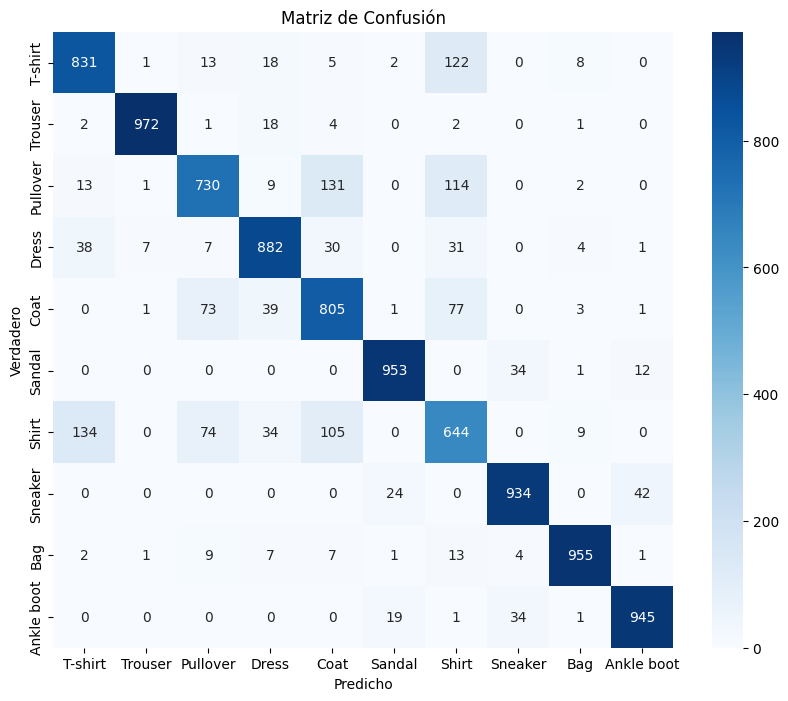

Reporte de Clasificación:
              precision    recall  f1-score   support

     T-shirt       0.81      0.83      0.82      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.80      0.73      0.77      1000
       Dress       0.88      0.88      0.88      1000
        Coat       0.74      0.81      0.77      1000
      Sandal       0.95      0.95      0.95      1000
       Shirt       0.64      0.64      0.64      1000
     Sneaker       0.93      0.93      0.93      1000
         Bag       0.97      0.95      0.96      1000
  Ankle boot       0.94      0.94      0.94      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



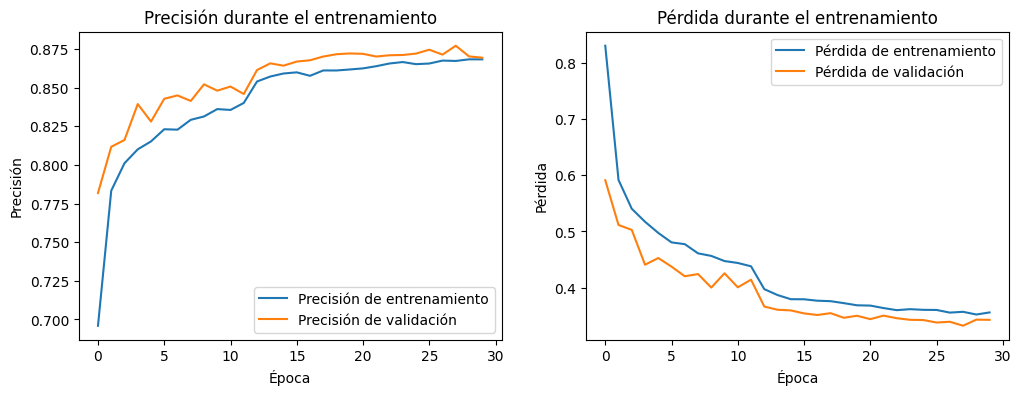

In [6]:

# Crear el modelo
modelo = crear_modelo_vit()

# Compilar el modelo
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)

# Entrenar el modelo (agrega callbacks)
historial = modelo.fit(
    datos_entrenamiento_x, datos_entrenamiento_y,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    verbose=1,
    callbacks=[early_stop, reduce_lr]  # Nueva línea
)

# Evaluar en el conjunto de prueba
perdida_prueba, precision_prueba = modelo.evaluate(datos_prueba_x, datos_prueba_y, verbose=0)
print(f'Precisión en el conjunto de prueba: {precision_prueba * 100:.2f}%')
# Predicciones
predicciones = modelo.predict(datos_prueba_x)
predicciones_clases = np.argmax(predicciones, axis=1)
etiquetas_prueba = np.argmax(datos_prueba_y, axis=1)

# Matriz de confusión
matriz_confusion = confusion_matrix(etiquetas_prueba, predicciones_clases)
print("Matriz de Confusión:")
print(matriz_confusion)

# Visualización (heatmap)
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues',
            xticklabels=['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'],
            yticklabels=['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'])
plt.title('Matriz de Confusión')
plt.xlabel('Predicho')
plt.ylabel('Verdadero')
plt.show()

# Métricas por clase (precision, recall, F1)
print("Reporte de Clasificación:")
print(classification_report(etiquetas_prueba, predicciones_clases,
                            target_names=['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']))
# Graficar el historial de entrenamiento
plt.figure(figsize=(12, 4))

# Gráfico de precisión
plt.subplot(1, 2, 1)
plt.plot(historial.history['accuracy'], label='Precisión de entrenamiento')
plt.plot(historial.history['val_accuracy'], label='Precisión de validación')
plt.title('Precisión durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()

# Gráfico de pérdida
plt.subplot(1, 2, 2)
plt.plot(historial.history['loss'], label='Pérdida de entrenamiento')
plt.plot(historial.history['val_loss'], label='Pérdida de validación')
plt.title('Pérdida durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()

plt.show()